In [17]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.container import BarContainer
from matplotlib.patches import Patch
from matplotlib.text import Text
from scipy import stats as sstats
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

REPO_ROOT = Path.cwd().parent.parent
# make the shared code in src/ importable even when the package is not pip-installed
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from egypt_survey_ml.config import DatasetConfig
from egypt_survey_ml.dataset import prepare_dataset
from egypt_survey_ml.explain import (combined_shap, plot_beeswarm,
                                     plot_importance)
from egypt_survey_ml.paths import DataPaths

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [3]:
# --- scenario settings -------------------------------------------------
# Every value below can be changed to test a different scenario. Defaults live in
# src/egypt_survey_ml/config.py (DatasetConfig); anything left out keeps its default
# (rng_seed=42, min_working_age=15, weeks_per_month=365.25/7/12).
# Column-selection workbook, separate from the command-area data_filename below.
# Sheet1: variable = column name, correl = 1 to include (0 to exclude), type = binary/
# categorical/numerical; remarks is ignored. Selected columns that are not in the data are
# skipped (same as the training notebooks). The saved models always get the columns they
# were trained on, so the mask only sets the default feature set of the dataset.
MASK_PATH = (
    Path.home()
    / "OneDrive - Stichting Deltares"
    / "Tiaravanni Hermawan's files - Egypt_ERF_data/Data/variable_selection.xlsx"
)

cfg = DatasetConfig(
    include_empstab=True,   # see design-decisions table above: circular under the zero-inclusive regime
    include_hrswk=True,     # team decision (Vanni's email) excludes hours for the female model;
                            # the audit branch's train-catboost_raw*.ipynb notebooks all keep it
                            # for female too. Toggle this to test how much of their higher
                            # reported R2 comes from that one feature, holding everything else
                            # (repeated eval, intensive-margin decomposition, wage formula, cap)
                            # fixed at our more rigorous setup.
    zero_handling="drop_random",   # one of: "none", "drop_random", "lognormal_synthetic"
    predict_log_wage=False,
    include_ribasim=True,
    wage_perturbation=False,
    wage_perturbation_sigma=0.03,
    drop_random_frac=1.0,   # only used when zero_handling == "drop_random"
    n_reps=100,             # change this
    male_outlier_cap=10000,
    female_outlier_cap=np.inf,
    data_filename="Data/ribasim_data/data_correlation_70.xlsx",
    male_exclude_columns = [
    "female_violence_sexual",
    "female_violence_emotional",
    "female_violence_physical",
    "female_child_married",
    "female_circumcised",
    "female_healthcare_decision",
    "female_contraceptives_decision",
    "female_labour_participation_rate",
    "female_unemployment_rate",
]
)

In [22]:
# Loads the survey, builds household wage context, makes the sex-stratified train/test split and the
# wage target, attaches governorates, and loads the command-area data and feature mask
# (see src/egypt_survey_ml/dataset.py).
_ONEDRIVE = "OneDrive - Stichting Deltares"
_EGYPT_DIR = "Tiaravanni Hermawan's files - Egypt_ERF_data"
_LFS_DIR = "Data/hh_data"

results_dir = Path.home() / _ONEDRIVE / _EGYPT_DIR / "Results"
results_dir.mkdir(parents=True, exist_ok=True)

paths = DataPaths.from_onedrive(
    onedrive_dir=_ONEDRIVE,
    egypt_dir=_EGYPT_DIR,
    lfs_dir=_LFS_DIR,
    data_filename=cfg.data_filename,
)
ds = prepare_dataset(cfg, paths=paths, mask_path=MASK_PATH)

train_pool = ds.train_pool
test_pool = ds.test_pool
survey_columns = ds.survey_columns
excel_df = ds.excel_df
EXCEL_PATH = ds.paths.excel_path

# dataset-bound helpers used by the cells below
assign_command_units = ds.assign_command_units
build_feature_frame = ds.build_feature_frame
apply_zero_handling = ds.apply_zero_handling

data source: OneDrive (/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ERF_data)
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ERF_data/Data/hh_data/Egypt 2022-LFS IND-V1.dta
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ERF_data/Data/hh_data/Egypt 2022-LFS HH-V1.dta
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ERF_data/Data/crosswalk/reg_governorate_crosswalk.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ERF_data/Data/crosswalk/command_area_governorate_crosswalk.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ERF_data/Data/variable_selection.xlsx
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ERF_data/Data/other_data/population_density_matrix.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's f

In [5]:
upper_egypt_govs = ['Aswan', 'Luxor', 'Quena', 'Suhag', 'Assyout', 'Menia', 'Beni-Suef', 'Fayoum', 'Cairo', 'Giza']

In [ ]:
from egypt_survey_ml.predict import load_members, predict_ensemble, describe, STAT_NAMES

RUN_ID = "20261116-141422" ##force monoton increase only for maize and sugarcane cotton

MODEL_DIR = REPO_ROOT / 'models/hp-tuned'

# One (seed, classifier, regressor) member per command-unit draw; the seeds come from model_metrics.csv
male_members = load_members(MODEL_DIR / f'classifiers-{RUN_ID}', MODEL_DIR / f'regressors-{RUN_ID}', 'male', seeds=None)
female_members = load_members(MODEL_DIR / f'classifiers-{RUN_ID}', MODEL_DIR / f'regressors-{RUN_ID}', 'female', seeds=None)

In [7]:
# One example draw (seed 0) of the training frame, for exploring the data in the cells below
from egypt_survey_ml.dataset import TARGET_COLS

train_geo = ds.assign_command_units(train_pool, seed=0)
train_frame, _, _ = ds.build_feature_frame(train_geo, sex_code=2)
feature_cols = [c for c in train_frame.columns if c not in TARGET_COLS]

In [8]:
# Every member predicts on the command-unit draw it was trained on (its seed).
# Each model picks its own feature columns, so the with/without RIBASIM models need no extra arguments.

# Specify 'governorates' to only predict for certain governorates.
pred_male = predict_ensemble(ds, male_members, 'male')
pred_female = predict_ensemble(ds, female_members, 'female')

In [9]:
# female: hard classification at P(paid) >= 0.33; male: predicted wage weighted by P(paid)
r2_scores_female = pred_female.r2_per_member()
r2_scores_male = pred_male.r2_per_member()

r2_summary = pd.DataFrame({
    "metric": STAT_NAMES,
    "r2_female": describe(r2_scores_female),
    "r2_male": describe(r2_scores_male),
})

# r2_summary.to_csv('r2_summary_ribasim_with_hrs.csv')

In [10]:
r2_summary

,metric,r2_female,r2_male
0,p5,0.497657,0.310045
1,p10,0.504669,0.313996
2,p20,0.522089,0.325902
3,p30,0.532470,0.336145
4,p40,0.538652,0.343236
5,p45,0.540989,0.344420
6,p50,0.543692,0.345035
7,p55,0.546394,0.346672
8,p60,0.548578,0.348178
9,p70,0.553674,0.350828


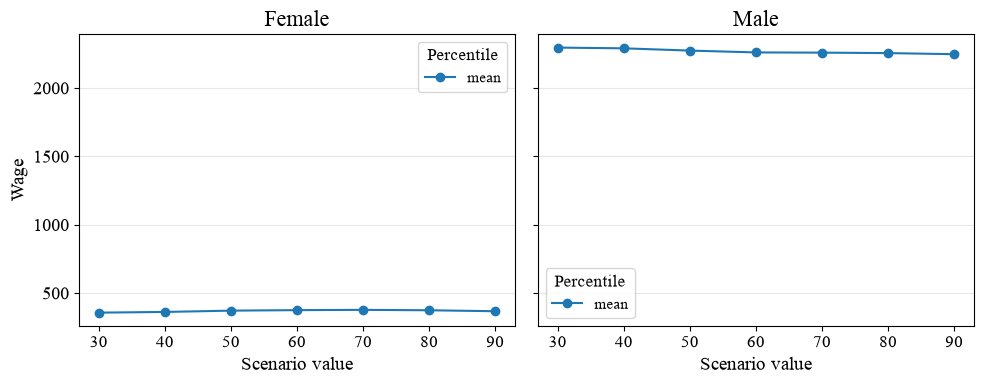

,female_30,male_30,female_40,male_40,female_50,male_50,female_60,male_60,female_70,male_70,female_80,male_80,female_90,male_90,female_95,male_95
p5,20.161721,1408.412271,20.909872,1333.305082,20.648784,1256.767320,18.339951,1251.162049,18.249095,1253.387442,18.019433,1242.153422,18.364647,1260.815807,21.455317,1232.265829
p10,32.168896,1760.069359,31.845004,1757.849064,29.093069,1697.876331,27.131817,1657.389528,26.850951,1631.943723,26.407553,1619.239952,26.962527,1664.859173,29.965843,1732.117750
p20,47.129939,1963.227498,45.023203,1959.663832,45.759862,1913.455704,41.750801,1878.845067,42.338862,1874.436881,40.570867,1867.280743,40.307229,1905.322908,42.455736,1962.054402
p30,59.394776,2140.798395,57.917725,2115.781283,58.239989,2075.152053,55.043993,2049.686137,55.596628,2039.538167,52.982822,2035.432341,52.166188,2067.212182,54.472624,2100.304008
p40,74.183573,2228.585714,72.149748,2206.231117,76.987385,2182.356228,76.217733,2159.767671,74.615815,2150.705647,71.566909,2147.052768,69.429692,2164.487467,66.681244,2188.219889
p45,86.248076,2265.723389,80.453495,2248.519304,88.106537,2222.135451,87.814647,2205.660031,88.533056,2197.728803,83.627647,2192.754530,79.093675,2201.706057,75.961493,2223.778367
p50,95.737760,2308.861818,95.294195,2295.844069,103.560211,2277.890238,105.786838,2260.933859,104.883155,2250.751729,103.684593,2247.983880,95.830020,2248.567284,88.747338,2261.944181
p55,116.168489,2354.414960,112.042749,2344.728814,124.944469,2329.342764,127.717197,2317.809280,127.359775,2312.418867,124.321976,2310.713713,115.608529,2311.640158,99.603613,2310.102703
p60,132.998775,2396.052365,138.153549,2389.697692,153.998578,2387.149626,159.182355,2376.785230,162.044557,2377.018851,160.693337,2378.145934,145.421161,2370.801909,122.839266,2359.484593
p70,191.966536,2520.760598,202.003313,2511.918350,226.286792,2526.547846,243.936513,2524.455927,247.350445,2530.620848,237.496212,2527.824344,213.479082,2503.385111,194.197203,2483.822306


In [20]:
wage_dict = {}
scenario_predictions = {}
for ribasim_run in ["30", "40", "50", "60", "70", "80", "90", "95"]:
    ribasim_excel_df = pd.read_excel(EXCEL_PATH.with_name(f"data_correlation_{ribasim_run}.xlsx"), sheet_name="command_unit")
    scenario_predictions[ribasim_run] = {
        'female': predict_ensemble(ds, female_members, 'female', excel_df=ribasim_excel_df),
        'male': predict_ensemble(ds, male_members, 'male', excel_df=ribasim_excel_df),
    }

    for sex in ['female', 'male']:
        pred = scenario_predictions[ribasim_run][sex]
        wage_dict[f'{sex}_{ribasim_run}'] = describe(pred.final_wage(aggregate="mean"), weights=pred.weight)

wage_df = pd.DataFrame(wage_dict, index=STAT_NAMES)

PERCENTILES = ["mean"]
X_VALUES = [30, 40, 50, 60, 70, 80, 90]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, gender in zip(axes, ["female", "male"]):
    columns = [f"{gender}_{x}" for x in X_VALUES]

    for percentile in PERCENTILES:
        wages = wage_df.loc[percentile, columns]
        ax.plot(X_VALUES, wages, marker="o", label=percentile)

    ax.set_title(gender.capitalize())
    ax.set_xlabel("Scenario value")
    ax.set_xticks(X_VALUES)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Percentile")

axes[0].set_ylabel("Wage")
plt.tight_layout()
plt.show()

wage_df

In [23]:
runs = ["30", "40", "50", "60", "70", "80", "90"]
thresholds = {"female": 0.34, "male": 0.47}
areas = ds.excel_df["area"].dropna().unique()
results = []

for sex, cutoff in thresholds.items():
    for run in runs:
        pred = scenario_predictions[run][sex]
        paid = pred.cls_prob >= cutoff
        by_area = pred.mean_by_command_unit(values=100 * paid, units=areas, weighted=False)
        by_area = by_area.rename_axis("area").rename(columns={"wage": "pct_paid"}).reset_index()
        results.append(by_area.assign(sex=sex, scenario=int(run), threshold=cutoff))

map_df = pd.concat(results, ignore_index=True)[["area", "sex", "scenario", "pct_paid", "threshold", "n_draws"]]
map_df.to_csv(results_dir / "paid_work_share_thresholded.csv", index=False)

In [24]:
results = []

for sex in ["female", "male"]:
    for run in runs:
        pred = scenario_predictions[run][sex]
        by_area = pred.mean_by_command_unit(values=100 * pred.cls_prob, units=areas, weighted=False)
        by_area = by_area.rename_axis("area").rename(columns={"wage": "pct_paid"}).reset_index()
        results.append(by_area.assign(sex=sex, scenario=int(run), threshold=np.nan))

map_df = pd.concat(results, ignore_index=True)[["area", "sex", "scenario", "pct_paid", "threshold", "n_draws"]]
map_df.to_csv(results_dir / "unemployment_rate.csv", index=False)
map_df

,area,sex,scenario,pct_paid,threshold,n_draws
0,Blk_Air_1,female,30,13.644330,NaN,90
1,Blk_Air_2,female,30,10.086264,NaN,100
2,Blk_Air_6,female,30,NaN,NaN,0
3,Blk_Air_7,female,30,21.214165,NaN,100
4,Blk_Air_8,female,30,23.014486,NaN,88
...,...,...,...,...,...,...
835,Blk_Air_60,male,90,96.938657,NaN,100
836,Blk_Air_62,male,90,89.072936,NaN,100
837,Blk_Air_63,male,90,90.950249,NaN,100
838,Blk_Air_65,male,90,89.170254,NaN,100


In [13]:
# Mean predicted wage per command unit: survey-weighted mean within each draw, then averaged over the draws.
# A unit without respondents in every draw is NaN.
wage_by_command_unit = pd.DataFrame({
    sex: pred.mean_by_command_unit(units=ds.excel_df["area"])["wage"]
    for sex, pred in [("female", pred_female), ("male", pred_male)]
})

wage_by_command_unit

wage_by_command_unit_dict = {}
for ribasim_run, preds in scenario_predictions.items():
    print(f"Ribasim run: {ribasim_run}")
    for sex, pred in preds.items():
        wage_by_command_unit_dict[f"{sex}_{ribasim_run}"] = pred.mean_by_command_unit(units=ds.excel_df["area"])["wage"]

wage_by_command_unit_df = pd.DataFrame(wage_by_command_unit_dict, index=ds.excel_df["area"])
wage_by_command_unit_df.to_csv(REPO_ROOT / 'output/wage_by_command_unit.csv')

Ribasim run: 30
Ribasim run: 40
Ribasim run: 50
Ribasim run: 60
Ribasim run: 70
Ribasim run: 80
Ribasim run: 90
Ribasim run: 95


In [14]:
# Feature importance of the combined model (classifier x regressor, all draws): SHAP values of both models are
# converted to EGP, combined so they add up to P(paid) * wage, and averaged over the ensemble members.
# Takes roughly 12 minutes for both sexes (SHAP for every member).

FIGURE_DIR = REPO_ROOT / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)

shap_male = combined_shap(ds, male_members, 'male')
shap_female = combined_shap(ds, female_members, 'female')

importance = pd.DataFrame({
    'male': shap_male.importance(weighted=True),
    'female': shap_female.importance(weighted=True),
}).sort_values('male', ascending=False)

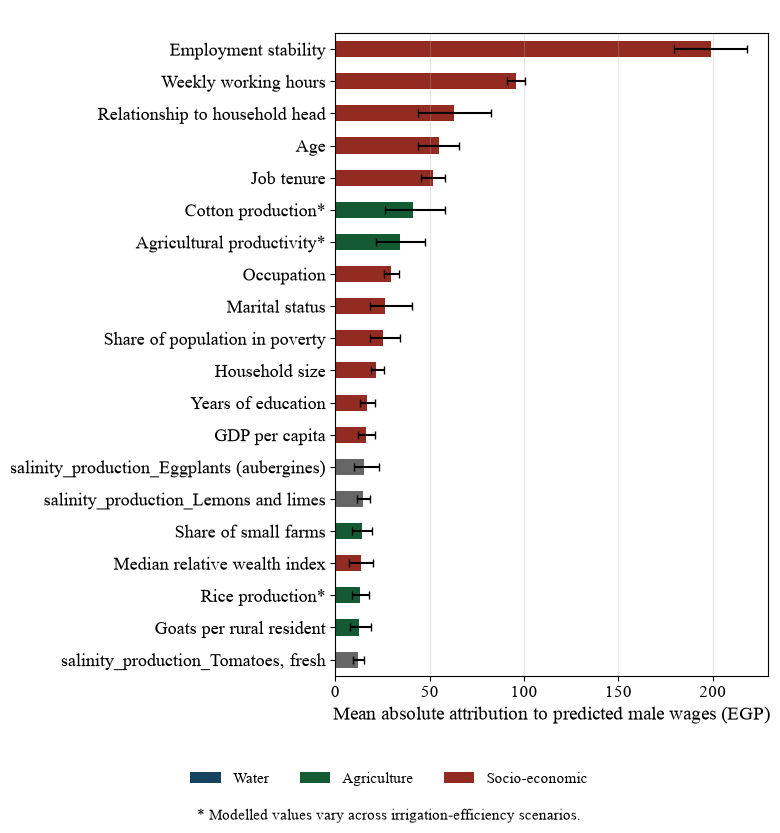

/Users/hemert/projects/egypt-survey-ml/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


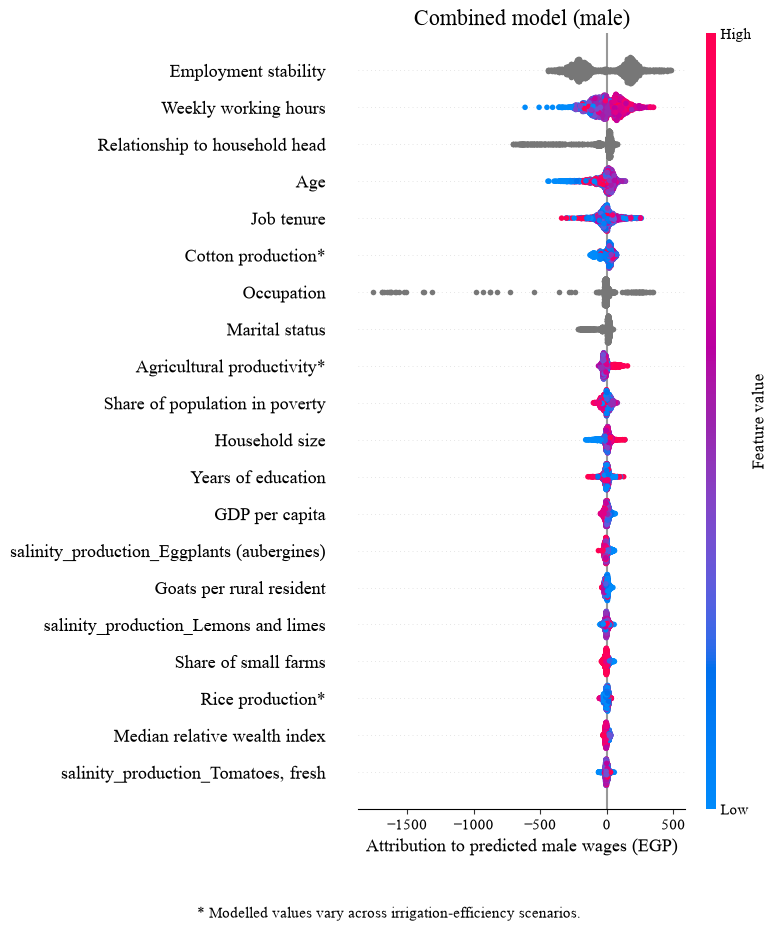

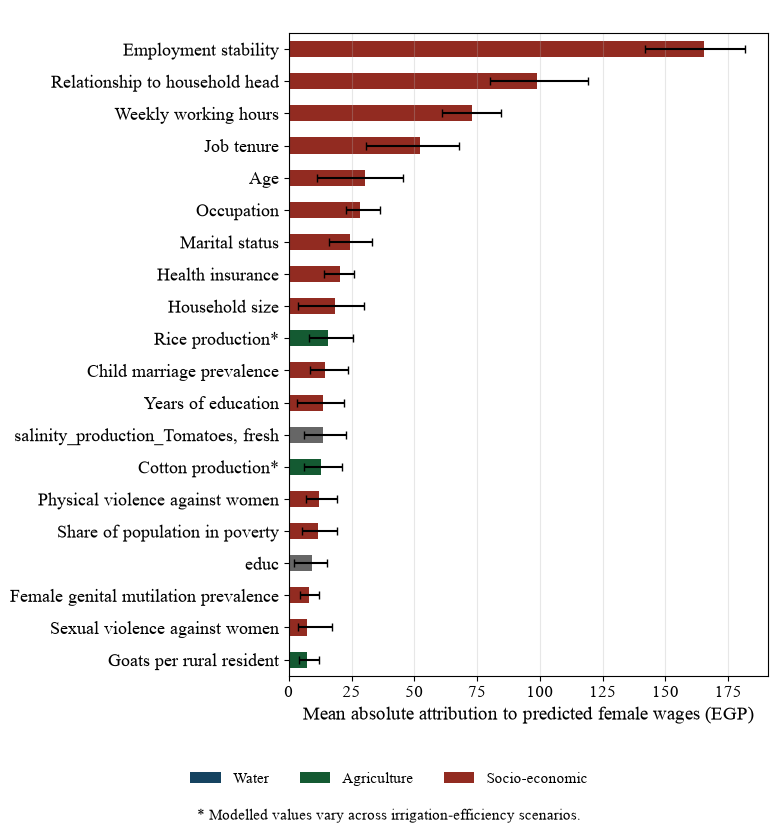

/Users/hemert/projects/egypt-survey-ml/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


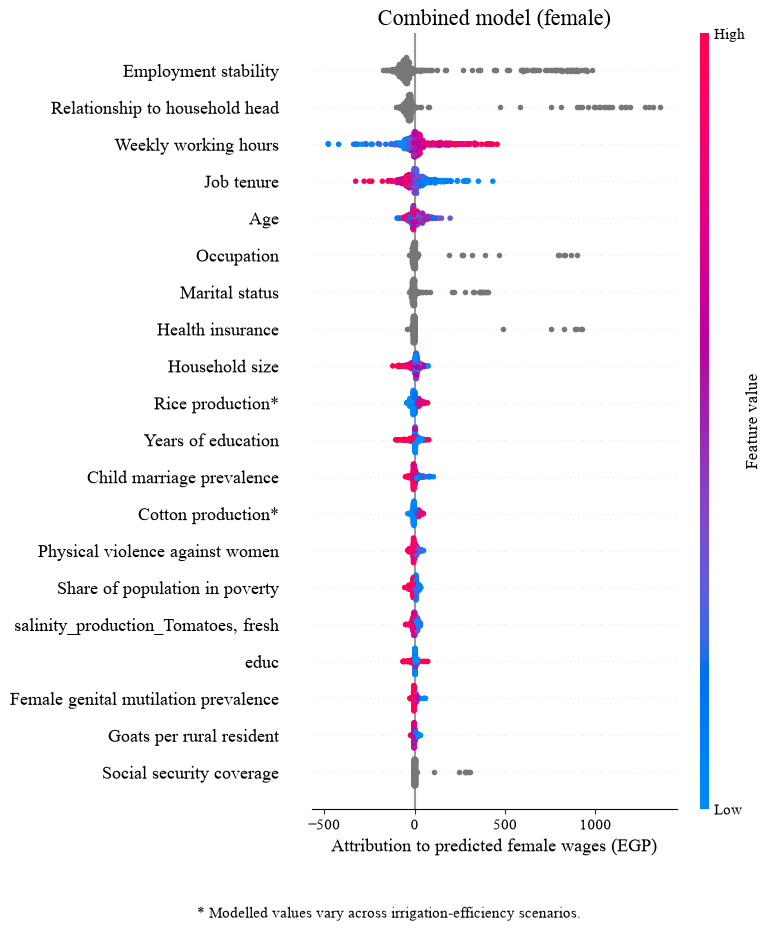

,male,female
Employment stability,197.501208,162.418149
Weekly working hours,91.820221,71.763117
Relationship to household head,62.881470,98.099992
Age,51.019271,27.719424
Job tenure,45.926873,51.158080
Cotton production*,33.452652,10.817538
Occupation,27.883690,25.050882
Agricultural productivity*,26.020860,1.906437
Marital status,25.930278,23.002893
Share of population in poverty,20.522194,10.577591


In [18]:
feature_labels = {
    # Socio-economic indicators
    "empstab": "Employment stability",
    "hrswk": "Weekly working hours",
    "rel": "Relationship to household head",
    "tenure": "Job tenure",
    "age": "Age",
    "occ": "Occupation",
    "household_size": "Household size",
    "mart_d": "Marital status",
    "yeduc": "Years of education",
    "hlthins": "Health insurance",
    "socsec": "Social security coverage",
    "p_poor_population": "Share of population in poverty",
    "gdp_pc": "GDP per capita",
    "rwi_median": "Median relative wealth index",
    # Governorate-level gender indicators
    "female_contraceptives_decision": "Women's contraceptive decision-making",
    "female_child_married": "Child marriage prevalence",
    "female_circumcised": "Female genital mutilation prevalence",
    "female_violence_physical": "Physical violence against women",
    "female_violence_sexual": "Sexual violence against women",
    "female_healthcare_decision": "Women's healthcare decision-making",
    "female_labour_participation_rate": "Female labour force participation",
    # Livestock indicators
    "chicken": "Chickens per rural resident",
    "cattle": "Cattle per rural resident",
    "goats": "Goats per rural resident",
    # Agricultural and water indicators
    "producer_price": "Agricultural productivity*",
    "salinity_production_Rice, paddy": "Rice production*",
    "salinity_production_Wheat": "Wheat production*",
    "salinity_production_Alfalfa for forage": "Alfalfa production*",
    "salinity_production_Sugar beet": "Sugar beet production*",
    "salinity_production_Cotton linters": "Cotton production*",
    "salinity_production_Sugar cane": "Sugar cane production*",
    "water_productivity": "Water productivity*",
    "fraction_small": "Share of small farms",
}

# Fonts and feature-group colours
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman"], "font.size": 14, "axes.titlesize": 16, "axes.labelsize": 14, "xtick.labelsize": 12, "ytick.labelsize": 13, "legend.fontsize": 11, "text.color": "black", "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black", "pdf.fonttype": 42, "ps.fonttype": 42})
productivity_features = {"salinity_production_Cotton linters", "producer_price", "salinity_production_Rice, paddy", "salinity_production_Wheat", "salinity_production_Alfalfa for forage", "fraction_small", "chicken", "cattle", "goats"}
water_features = {"water_productivity"}
productivity_color, water_color, socioeconomic_color = "#145A32", "#154360", "#922B21"
feature_colors = {feature: (productivity_color if feature in productivity_features else water_color if feature in water_features else socioeconomic_color) for feature in feature_labels}
legend_handles = [Patch(facecolor=water_color, label="Water"), Patch(facecolor=productivity_color, label="Agriculture"), Patch(facecolor=socioeconomic_color, label="Socio-economic")]
scenario_note = "* Modelled values vary across irrigation-efficiency scenarios."

FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
importance = pd.DataFrame({"male": shap_male.importance(weighted=True), "female": shap_female.importance(weighted=True)}).drop(index="V", errors="ignore").sort_values("male", ascending=False)

for sex, res in [("male", shap_male), ("female", shap_female)]:
    # Feature importance: coloured bars and black text
    # bars: mean over ensemble members; error bars: 90% interval across members
    plot_importance(res.importance_band(weighted=True, level=0.9).drop(index="V", errors="ignore"), top=20, title=f" ")#Feature importance, combined model ({sex})
    ax = plt.gca()
    fig = ax.figure
    original_labels = [tick.get_text() for tick in ax.get_yticklabels()]
    tick_positions = ax.get_yticks()
    for container in ax.containers:
        if isinstance(container, BarContainer):
            for bar in container.patches:
                bar_center = bar.get_y() + bar.get_height() / 2
                nearest_tick = min(range(len(tick_positions)), key=lambda i: abs(tick_positions[i] - bar_center))
                bar.set_facecolor(feature_colors.get(original_labels[nearest_tick], "#666666"))
                bar.set_edgecolor("none")
    ax.set_yticks(tick_positions, labels=[feature_labels.get(feature, feature) for feature in original_labels])
    ax.set_xlabel(f"Mean absolute attribution to predicted {sex} wages (EGP)")
    ax.set_ylabel("")
    fig.legend(handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, 0.045), ncol=3, frameon=False)
    fig.text(0.5, 0.018, scenario_note, ha="center", va="bottom", fontsize=11, color="black")
    for text in fig.findobj(match=Text):
        text.set_fontfamily("Times New Roman")
        text.set_color("black")
    fig.tight_layout(rect=[0, 0.11, 1, 1])
    fig.savefig(FIGURE_DIR / f"shap-importance-combined-{sex}.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Beeswarm: retain feature-value dot colours; V must be filtered within plot_beeswarm
    plot_beeswarm(res, top=20, title=f"Combined model ({sex})", show=False)
    ax = plt.gca()
    fig = ax.figure
    original_labels = [tick.get_text() for tick in ax.get_yticklabels()]
    ax.set_yticks(ax.get_yticks(), labels=[feature_labels.get(feature, feature) for feature in original_labels])
    ax.set_xlabel(f"Attribution to predicted {sex} wages (EGP)")
    ax.set_ylabel("")
    # No group legend here because neither dots nor labels encode feature groups.
    fig.text(0.5, 0.018, scenario_note, ha="center", va="bottom", fontsize=11, color="black")
    for text in fig.findobj(match=Text):
        text.set_fontfamily("Times New Roman")
        text.set_color("black")
    fig.tight_layout(rect=[0, 0.065, 1, 1])
    fig.savefig(FIGURE_DIR / f"shap-beeswarm-combined-{sex}.png", dpi=300, bbox_inches="tight")
    plt.show()

# Importance table with readable labels
importance.rename(index=feature_labels)

In [29]:
# Feature importance of the combined model (classifier x regressor, all draws): SHAP values of both models are
# converted to EGP, combined so they add up to P(paid) * wage, and averaged over the ensemble members.
# Takes roughly 12 minutes for both sexes (SHAP for every member).
from egypt_survey_ml.explain import combined_shap, plot_importance, plot_beeswarm

FIGURE_DIR = REPO_ROOT / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)

shap_male = combined_shap(ds, male_members, 'male')
shap_female = combined_shap(ds, female_members, 'female')

importance = pd.DataFrame({
    'male': shap_male.importance(weighted=True),
    'female': shap_female.importance(weighted=True),
}).sort_values('male', ascending=False)

for sex, res in [('male', shap_male), ('female', shap_female)]:
    plot_importance(res.importance(weighted=True), top=20, title=f'Feature importance, combined model ({sex})')
    # plt.savefig(FIGURE_DIR / f'shap-importance-combined-{sex}.png')
    plt.show()

    # beeswarm: x = effect on the predicted wage (EGP), colour = feature value (grey = categorical)
    plot_beeswarm(res, top=20, title=f'Combined model ({sex})', show=False)
    # plt.savefig(FIGURE_DIR / f'shap-beeswarm-combined-{sex}.png', bbox_inches='tight')
    plt.show()

importance

KeyboardInterrupt: 

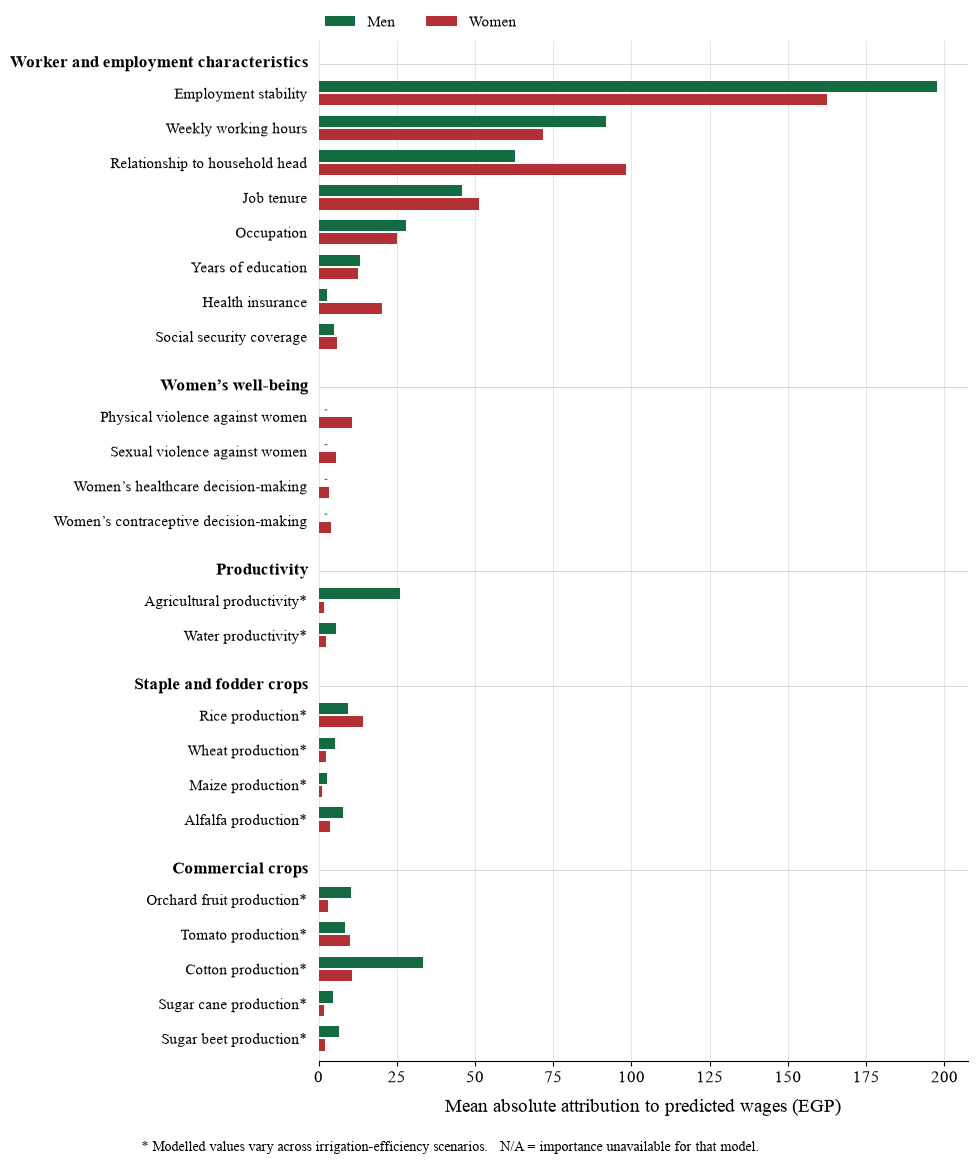

,Men,Women
Employment stability,197.501208,162.418149
Weekly working hours,91.820221,71.763117
Relationship to household head,62.881470,98.099992
Job tenure,45.926873,51.158080
Occupation,27.883690,25.050882
Years of education,13.404688,12.566863
Health insurance,2.682641,20.262758
Social security coverage,4.857164,5.984250
Physical violence against women,NaN,10.777223
Sexual violence against women,NaN,5.706733


In [19]:
# Group order and variable order are both preserved in the figure.
feature_groups = {
    "Worker and employment characteristics": {
        "empstab": "Employment stability",
        "hrswk": "Weekly working hours",
        "rel": "Relationship to household head",
        "tenure": "Job tenure",
        "occ": "Occupation",
        "yeduc": "Years of education",
        "hlthins": "Health insurance",
        "socsec": "Social security coverage",
    },
    "Women’s well-being": {
        "female_violence_physical": "Physical violence against women",
        "female_violence_sexual": "Sexual violence against women",
        "female_healthcare_decision": "Women’s healthcare decision-making",
        "female_contraceptives_decision": "Women’s contraceptive decision-making",
    },
    "Productivity": {
        "producer_price": "Agricultural productivity*",
        "water_productivity": "Water productivity*",
    },
    "Staple and fodder crops": {
        "salinity_production_Rice, paddy": "Rice production*",
        "salinity_production_Wheat": "Wheat production*",
        "salinity_production_Maize (incl. 0067 and 0068)": "Maize production*",
        "salinity_production_Alfalfa for forage": "Alfalfa production*",
    },
    "Commercial crops": {
        "salinity_production_Lemons and limes": "Orchard fruit production*",
        "salinity_production_Tomatoes, fresh": "Tomato production*",
        "salinity_production_Cotton linters": "Cotton production*",
        "salinity_production_Sugar cane": "Sugar cane production*",
        "salinity_production_Sugar beet": "Sugar beet production*",
    },
}

feature_labels = {
    feature: label
    for group in feature_groups.values()
    for feature, label in group.items()
}

# Align the two models by feature name. Strip trailing spaces, including
# the one that can appear at the end of the maize feature name.
def weighted_importance(result):
    values = result.importance(weighted=True).copy()
    values.index = values.index.str.strip()
    return values

importance = pd.DataFrame({
    "Men": weighted_importance(shap_male),
    "Women": weighted_importance(shap_female),
}).reindex(list(feature_labels))

# Reserve one row for each group heading, then one row per variable.
heading_positions = {}
feature_positions = {}
row = 0.0

for group, features in feature_groups.items():
    heading_positions[group] = row
    row += 0.85
    for feature in features:
        feature_positions[feature] = row
        row += 1.0
    row += 0.45

y = np.array([feature_positions[f] for f in importance.index])

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 12,
    "pdf.fonttype": 42,
})

fig, ax = plt.subplots(figsize=(11, 12))
fig.subplots_adjust(left=0.38, right=0.97, top=0.95, bottom=0.10)

# The negative offset places the men's bar above the women's bar
# once the y-axis is inverted.
for sex, color, offset in [
    ("Men",   "#146B42", -0.19),
    ("Women", "#B33135",  0.19),
]:
    values = importance[sex]
    present = values.notna().to_numpy()

    ax.barh(
        y[present] + offset,
        values[present],
        height=0.32,
        color=color,
        edgecolor="none",
        label=sex,
        zorder=3,
    )

    for position in y[~present]:
        ax.annotate(
            "-", xy=(0, position + offset), xytext=(4, 0),
            textcoords="offset points", ha="left", va="center",
            fontsize=8, color=color,
        )

ax.set_yticks(y, labels=[feature_labels[f] for f in importance.index])
ax.tick_params(axis="y", length=0, pad=8, labelsize=11)

for group, position in heading_positions.items():
    ax.text(
        -0.015, position, group,
        transform=ax.get_yaxis_transform(),
        ha="right", va="center", fontsize=12, fontweight="bold",
        clip_on=False,
    )
    ax.axhline(position, color="#D8D8D8", linewidth=0.7, zorder=1)

ax.set_ylim(y[-1] + 0.65, -0.65)
ax.set_xlim(left=0)
ax.set_xlabel("Mean absolute attribution to predicted wages (EGP)", labelpad=9)
ax.grid(axis="x", color="#E6E6E6", linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)

ax.legend(
    loc="lower left", bbox_to_anchor=(0, 1.005),
    ncol=2, frameon=False, borderaxespad=0,
)

note = "* Modelled values vary across irrigation-efficiency scenarios."
if importance.isna().any().any():
    note += "   N/A = importance unavailable for that model."
fig.text(0.5, 0.025, note, ha="center", fontsize=10)

FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(
    FIGURE_DIR / "shap-importance-men-women.png",
    dpi=300, bbox_inches="tight", pad_inches=0.15,
)
plt.show()

# Display the corresponding table in the same order as the figure.
importance.rename(index=feature_labels)

In [19]:
wage_df.to_csv("/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/predicted_wage/wages_predictions_upper.csv")
nonzero_wage_df.to_csv("/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/predicted_wage/nonzero_wages_predictions_upper.csv")

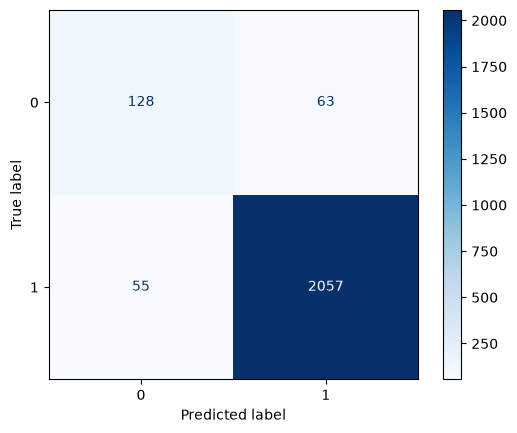

In [16]:
prediction_paid_male = pred_male.predicted_paid(threshold=0.70)
prediction_final_male = pred_male.final_wage()
true_paid_male = pred_male.true_paid
true_income_male = pred_male.true_income

y_pred = prediction_paid_male.astype(float)
y_true = true_paid_male

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

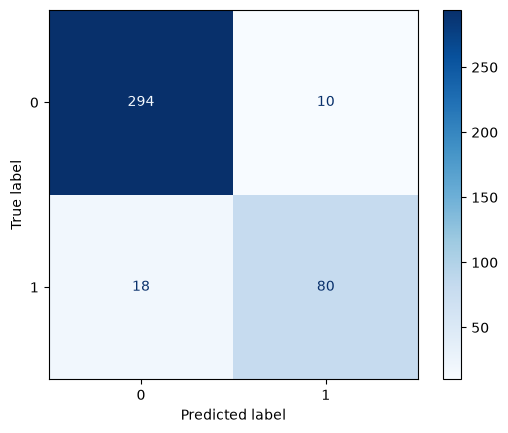

In [17]:
prediction_paid_female = pred_female.predicted_paid(threshold=0.33)
prediction_final_female = pred_female.final_wage()
true_paid_female = pred_female.true_paid
true_income_female = pred_female.true_income

y_pred = prediction_paid_female.astype(float)
y_true = true_paid_female

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

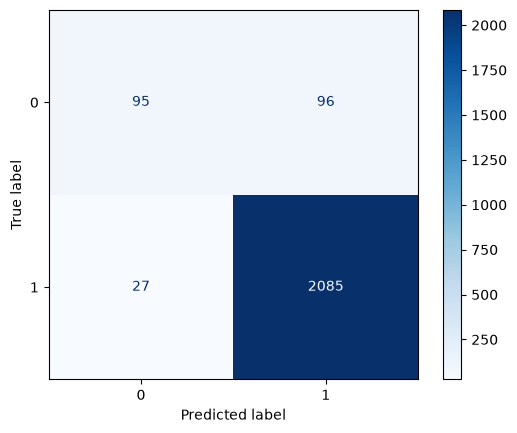

In [18]:
prediction_paid_male_nr = pred_male_nr.predicted_paid()
prediction_final_male_nr = pred_male_nr.final_wage()

y_pred = prediction_paid_male_nr.astype(float)
y_true = true_paid_male

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

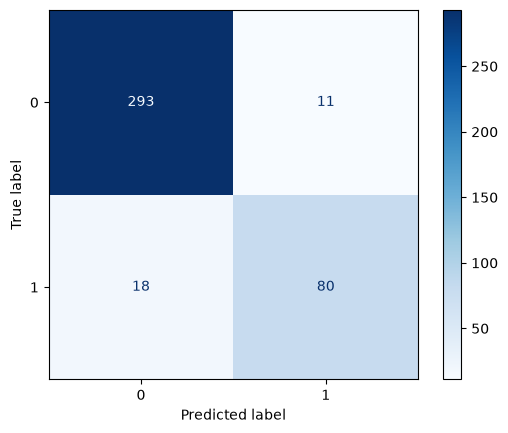

In [19]:
prediction_paid_female_nr = pred_female_nr.predicted_paid(threshold=0.33)
prediction_final_female_nr = pred_female_nr.final_wage()

y_pred = prediction_paid_female_nr.astype(float)
y_true = true_paid_female

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

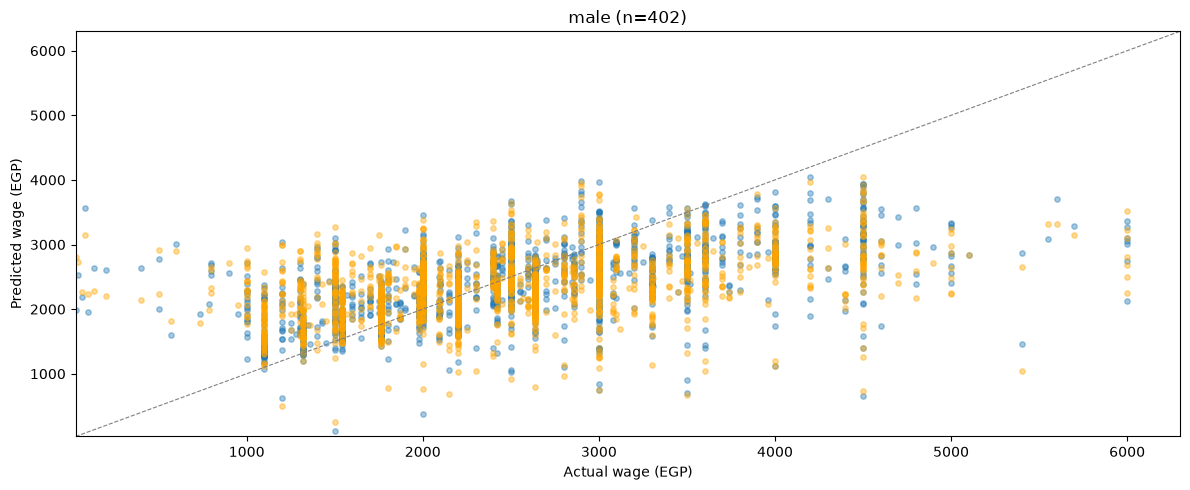

{'n': 2112, 'mae': 492.51337303529283, 'r2': 0.3409663646224297, 'spearman': np.float64(0.6289127174956083)}


In [20]:
fig, ax = plt.subplots(figsize=(12, 5))
y_pred_male = prediction_final_male
y_true_male = true_income_male
y_pred_nr_male = prediction_final_male_nr

y_pred_male = y_pred_male[y_true_male > 0]
y_pred_nr_male = y_pred_nr_male[y_true_male > 0]
y_true_male = y_true_male[y_true_male > 0]

ax.scatter(y_true_male, y_pred_male, alpha=0.4, s=15)
ax.scatter(y_true_male, y_pred_nr_male, alpha=0.4, s=15, color='orange')
lims = [0.95 * min(y_true_male.min(), y_pred_male.min()), max(y_true_male.max(), y_pred_male.max()) * 1.05]
ax.plot(lims, lims, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual wage (EGP)")
ax.set_title(f"male (n={len(y_true)})")
ax.set_ylabel("Predicted wage (EGP)")
plt.tight_layout()
plt.show()

metrics = {
    "n": len(y_true_male),
    "mae": mean_absolute_error(y_true_male, y_pred_male),
    "r2": r2_score(y_true_male, y_pred_male),
    "spearman": sstats.spearmanr(y_true_male, y_pred_male).correlation,
}
print(metrics)

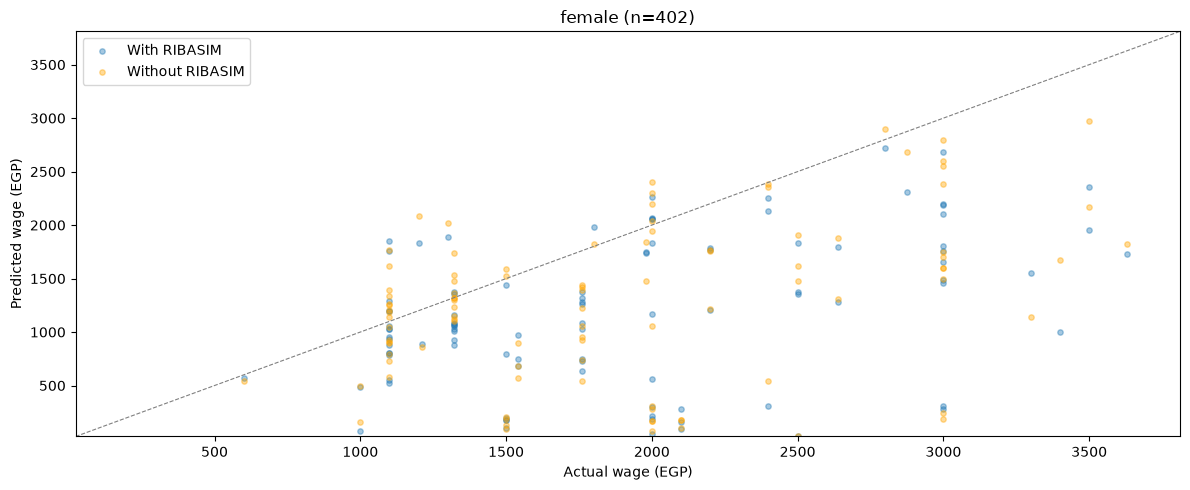

{'n': 98, 'mae': 795.660524689038, 'r2': -1.0856729934662672, 'spearman': np.float64(0.3796786213813294)}
{'n': 98, 'mae': 747.76866085625, 'r2': -0.9873848392178302, 'spearman': np.float64(0.3584657714033742)}


In [21]:
fig, ax = plt.subplots(figsize=(12, 5))
y_pred_female = prediction_final_female
y_pred_nr_female = prediction_final_female_nr
y_true_female = true_income_female

y_pred_female = y_pred_female[y_true_female > 0]
y_pred_nr_female = y_pred_nr_female[y_true_female > 0]
y_true_female = y_true_female[y_true_female > 0]

ax.scatter(y_true_female, y_pred_female, alpha=0.4, s=15, label='With RIBASIM')
ax.scatter(y_true_female, y_pred_nr_female, alpha=0.4, s=15, color='orange', label='Without RIBASIM')
lims = [0.95 * min(y_true_female.min(), y_pred_female.min()), max(y_true_female.max(), y_pred_female.max()) * 1.05]
ax.plot(lims, lims, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual wage (EGP)")
ax.set_title(f"female (n={len(y_true)})")
ax.set_ylabel("Predicted wage (EGP)")
ax.legend()
plt.tight_layout()
plt.show()

metrics = {
    "n": len(y_true_female),
    "mae": mean_absolute_error(y_true_female, y_pred_female),
    "r2": r2_score(y_true_female, y_pred_female),
    "spearman": sstats.spearmanr(y_true_female, y_pred_female).correlation,
}
metrics_nr = {
    "n": len(y_true_female),
    "mae": mean_absolute_error(y_true_female, y_pred_nr_female),
    "r2": r2_score(y_true_female, y_pred_nr_female),
    "spearman": sstats.spearmanr(y_true_female, y_pred_nr_female).correlation,
}
print(metrics)
print(metrics_nr)

In [23]:
FIGURE_DIR = REPO_ROOT / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)

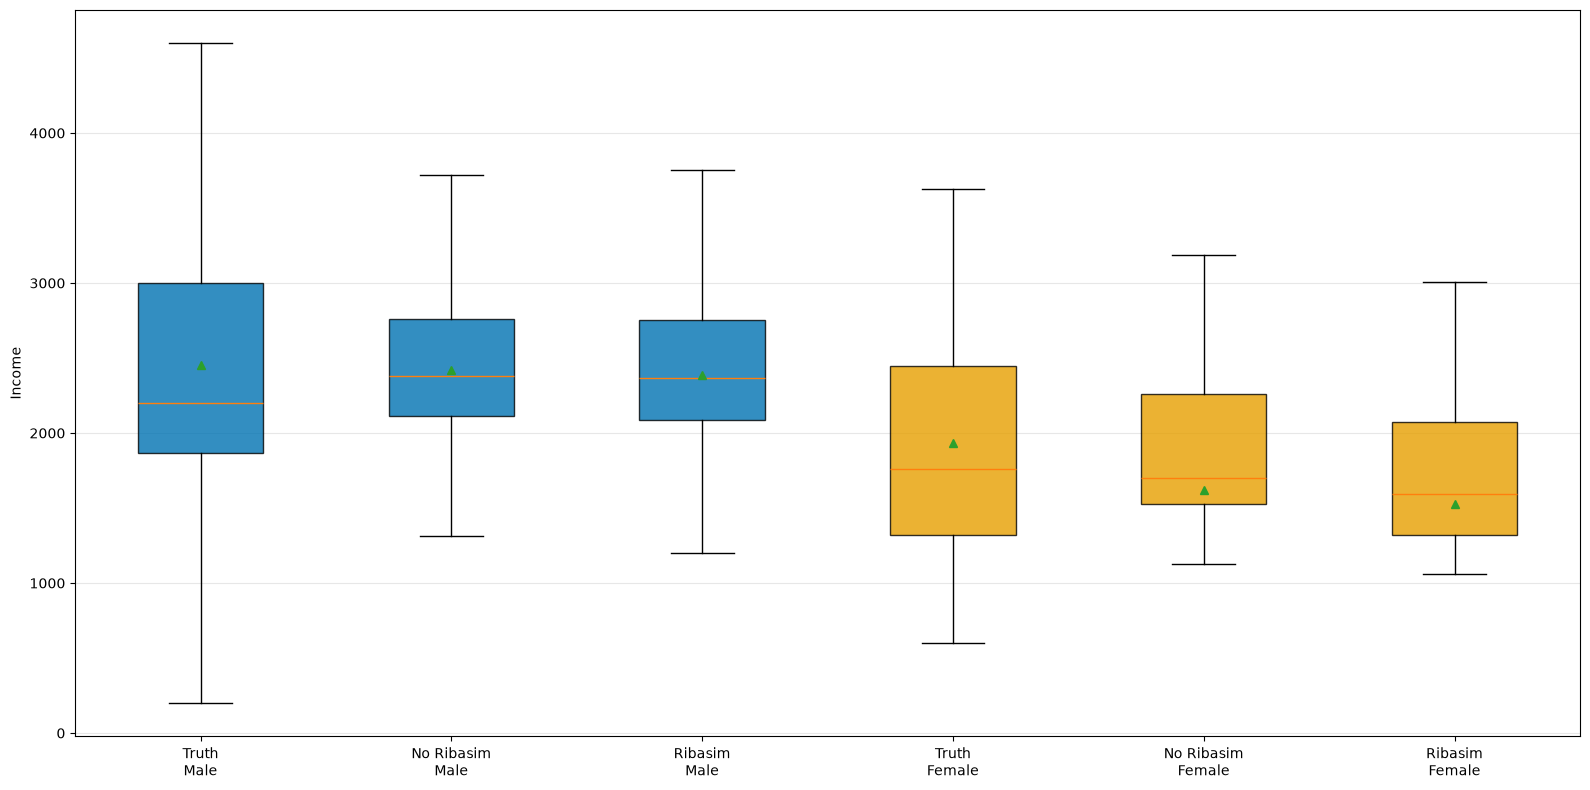

<Figure size 640x480 with 0 Axes>

In [65]:
y_pred_male = prediction_final_male
y_true_male = true_income_male
y_pred_nr_male = prediction_final_male_nr

y_pred_male = y_pred_male[y_true_male > 0]
y_pred_nr_male = y_pred_nr_male[y_true_male > 0]
y_true_male = y_true_male[y_true_male > 0]

y_pred_female = prediction_final_female
y_pred_nr_female = prediction_final_female_nr
y_true_female = true_income_female

y_pred_female = y_pred_female[y_true_female > 0]
y_pred_nr_female = y_pred_nr_female[y_true_female > 0]
y_true_female = y_true_female[y_true_female > 0]

fig, ax = plt.subplots(figsize=(16, 8))

data = [
    y_true_male,
    y_pred_nr_male,
    y_pred_male,
    y_true_female,
    y_pred_nr_female,
    y_pred_female,
]

labels = [
    "Truth\nMale",
    "No Ribasim\nMale",
    "Ribasim\nMale",
    "Truth\nFemale",
    "No Ribasim\nFemale",
    "Ribasim\nFemale",
]

bp = ax.boxplot(
    data,
    patch_artist=True,
    showmeans=True,
    showfliers=False,
)

colors = [
    "#0072B2", "#0072B2",
    "#0072B2", "#E69F00",
    "#E69F00", "#E69F00",
]

for box, color in zip(bp["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.8)

ax.set_xticklabels(labels)

ax.set_ylabel("Income")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(FIGURE_DIR / 'baseline-box-plots-with-hrs-22.png')

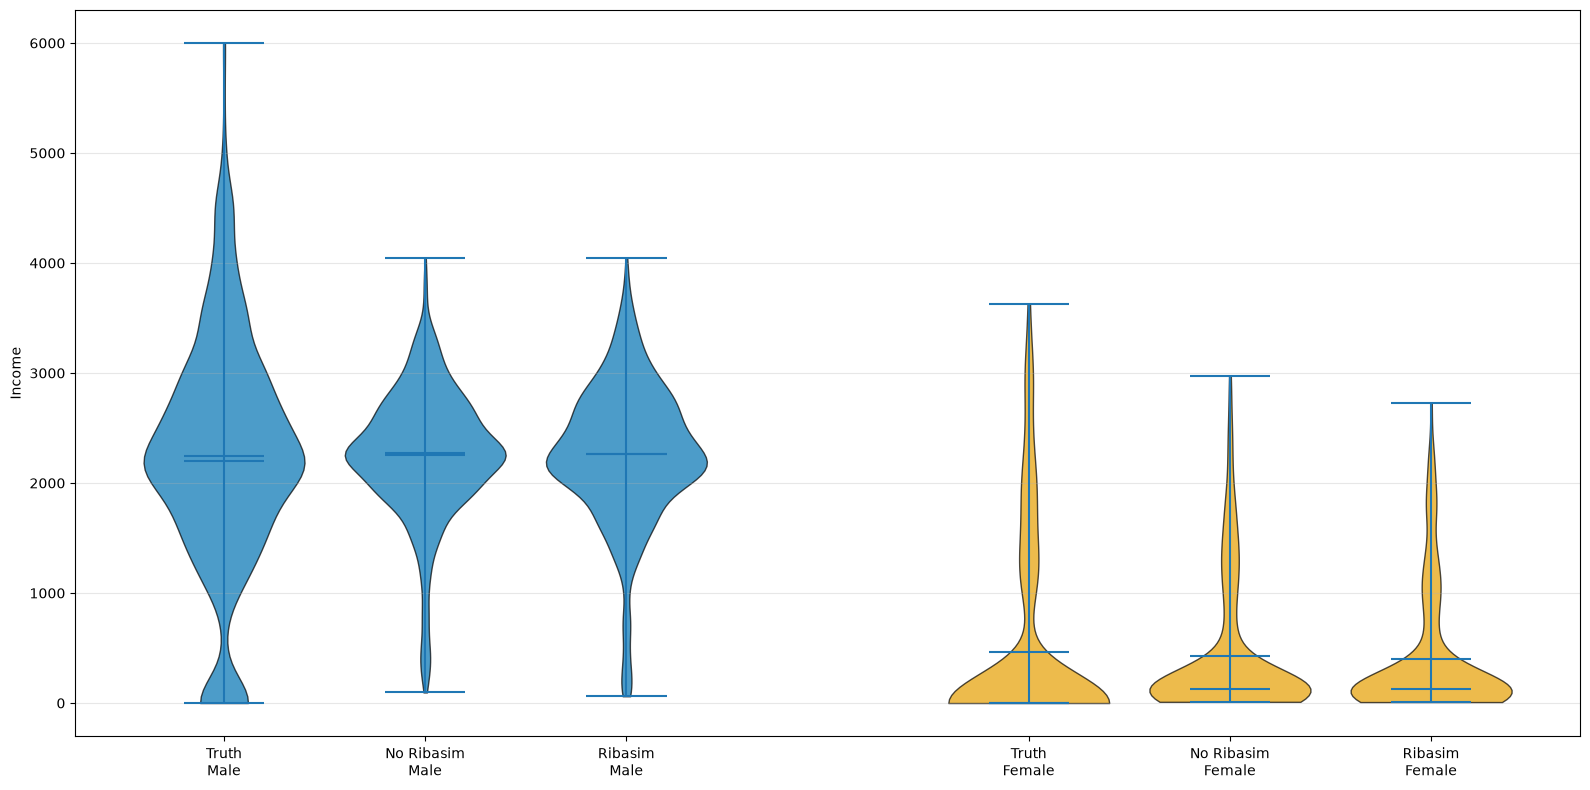

In [24]:
y_pred_male = prediction_final_male
y_true_male = true_income_male
y_pred_nr_male = prediction_final_male_nr

y_pred_female = prediction_final_female
y_pred_nr_female = prediction_final_female_nr
y_true_female = true_income_female

fig, ax = plt.subplots(figsize=(16, 8))

data = [
    y_true_male,
    y_pred_nr_male,
    y_pred_male,
    y_true_female,
    y_pred_nr_female,
    y_pred_female,
]

positions = [1, 2, 3, 5, 6, 7]

vp = ax.violinplot(
    data,
    positions=positions,
    widths=0.8,
    showmeans=True,
    showmedians=True,
)

colors = [
    "#0072B2", "#0072B2",  # Truth
    "#0072B2", "#E69F00",  # Ribasim
    "#E69F00", "#E69F00",  # No Ribasim
]

for body, color in zip(vp["bodies"], colors):
    body.set_facecolor(color)
    body.set_edgecolor("black")
    body.set_alpha(0.7)

ax.set_xticks(positions)
ax.set_xticklabels([
    "Truth\nMale",
    "No Ribasim\nMale",
    "Ribasim\nMale",
    "Truth\nFemale",
    "No Ribasim\nFemale",
    "Ribasim\nFemale",
])

ax.set_ylabel("Income")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
# plt.show()
plt.savefig(FIGURE_DIR / 'baseline-violin-plots-with-hrs-22.png')